<a href="https://colab.research.google.com/github/Kaybee125-alt/CodeAlpha_Handwritten_Character_Recognition/blob/main/Handwritten_Character_Recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Handwritten Character Recognition**

#**Introduction**

**Objective**

The objective of this project is to develop a deep learning model that can automatically recognise handwritten English capital letters (A–Z) from images. The model will learn visual patterns and features from handwritten characters to accurately classify each image according to its corresponding letter.

**Motivation**

Handwritten character recognition is a fundamental computer vision problem with a wide range of practical applications, including postal address recognition, form digitisation, bank cheque processing, and note-taking applications. However, handwritten letters can vary considerably in shape, size, style, and orientation between different individuals. Therefore, an effective recognition system must learn the underlying visual characteristics of each letter rather than simply memorising individual examples. Deep learning provides an appropriate approach for this task because it can automatically learn meaningful image features and complex patterns directly from training data.


#**Data Description**

The dataset used in this project is the **A–Z Handwritten Alphabets dataset**, obtained from Kaggle. The dataset is provided as a single CSV file, `A_Z Handwritten Data.csv`, and is derived from the **NIST Special Database 19**. It contains approximately 372,000 images of handwritten English capital letters (A–Z).

| **Property**            | **Description**                                                         |
| ----------------------- | ----------------------------------------------------------------------- |
| **Dataset**             | A–Z Handwritten Alphabets dataset                                       |
| **Source**              | Kaggle; derived from NIST Special Database 19                           |
| **Format**              | One CSV file, allowing efficient loading and processing in Google Colab |
| **Number of samples**   | Approximately 372,000 handwritten letter images                         |
| **Number of columns**   | 785 columns: 1 label column and 784 pixel columns                       |
| **Image dimensions**    | 28 × 28 pixels                                                          |
| **Image type**          | Greyscale                                                               |
| **Pixel values**        | Integer values ranging from 0 to 255                                    |
| **Labels**              | 26 classes, represented by integers 0–25                                |
| **Classification task** | Multi-class classification of handwritten capital letters               |

Each row in the dataset represents one handwritten letter image. The first column contains the class label, while the remaining 784 columns contain the pixel intensity values of the image. Since the pixels are stored as a single flattened vector, the 784 pixel values must be reshaped into a **28 × 28 two-dimensional image** before being provided to the Convolutional Neural Network (CNN). This representation allows the CNN to learn spatial patterns, such as edges, curves, and shapes, that distinguish one handwritten letter from another.


#**Setup**



In [ ]:
# Core libraries
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Deep learning
import tensorflow as tf
from tensorflow.keras import layers, models

# Evaluation and data splitting
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# Make results reproducible
np.random.seed(42)
tf.random.set_seed(42)

# Label index -> letter, e.g. 0 -> 'A'
letters = list(string.ascii_uppercase)

#**Load and Explore the Data**

In [ ]:
# Path to the dataset
DATA_PATH = "/content/A_Z Handwritten Data.csv"

MAX_ROWS = None

df = pd.read_csv(DATA_PATH, nrows=MAX_ROWS)

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Pixel value range:", df.iloc[:, 1:].values.min(), "to", df.iloc[:, 1:].values.max())

Dataset shape: (372450, 785)
Missing values: 0
Pixel value range: 0 to 255


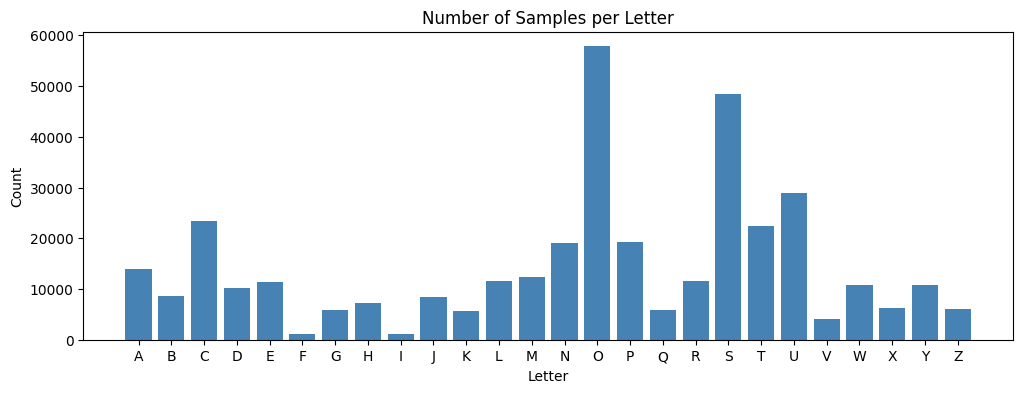

In [ ]:
# Class distribution
class_counts = df.iloc[:, 0].value_counts().sort_index()

plt.figure(figsize=(12, 4))
plt.bar(letters, class_counts.values, color="steelblue")
plt.title("Number of Samples per Letter")
plt.xlabel("Letter")
plt.ylabel("Count")
plt.show()

#**Data Pre-processing**



In [ ]:
# Separate labels and pixels
y = df.iloc[:, 0].values
X = df.iloc[:, 1:].values

# Reshape to images and normalise to [0, 1]
X = X.reshape(-1, 28, 28, 1).astype("float32") / 255.0

# Stratified train / validation / test split
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

# Free memory
del df, X, X_temp

print("Train:     ", X_train.shape)
print("Validation:", X_val.shape)
print("Test:      ", X_test.shape)

Train:      (297960, 28, 28, 1)
Validation: (37245, 28, 28, 1)
Test:       (37245, 28, 28, 1)


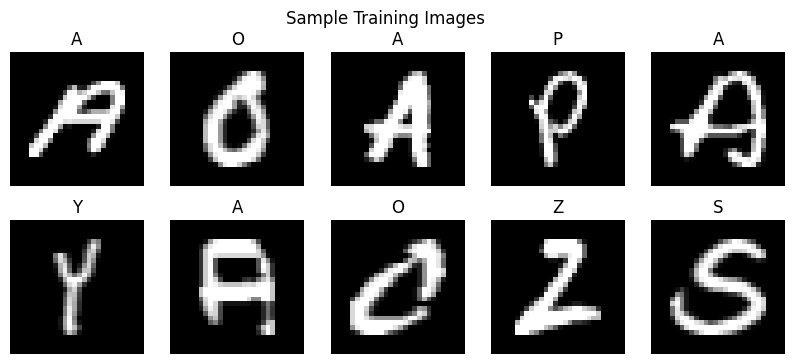

In [ ]:
# Visual check
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="gray")
    plt.title(letters[y_train[i]])
    plt.axis("off")
plt.suptitle("Sample Training Images")
plt.show()

#**Model Architecture**

In [ ]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Block 1: low-level features (edges, strokes)
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 2: higher-level features (curves, letter parts)
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classifier
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(26, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 227,098 (887.10 KB)

 Trainable params: 227,098 (887.10 KB)

 Non-trainable params: 0 (0.00 B)

#**Training**

In [ ]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=8,
    batch_size=128,
)

Epoch 1/8
2328/2328 ━━━━━━━━━━━━━━━━━━━━ 266s 113ms/step - accuracy: 0.9330 - loss: 0.2349 - val_accuracy: 0.9777 - val_loss: 0.0775
Epoch 2/8
2328/2328 ━━━━━━━━━━━━━━━━━━━━ 272s 117ms/step - accuracy: 0.9741 - loss: 0.0928 - val_accuracy: 0.9846 - val_loss: 0.0548
Epoch 3/8
2328/2328 ━━━━━━━━━━━━━━━━━━━━ 265s 114ms/step - accuracy: 0.9797 - loss: 0.0724 - val_accuracy: 0.9873 - val_loss: 0.0453
Epoch 4/8
2328/2328 ━━━━━━━━━━━━━━━━━━━━ 264s 113ms/step - accuracy: 0.9835 - loss: 0.0585 - val_accuracy: 0.9888 - val_loss: 0.0399
Epoch 5/8
2328/2328 ━━━━━━━━━━━━━━━━━━━━ 321s 113ms/step - accuracy: 0.9861 - loss: 0.0478 - val_accuracy: 0.9896 - val_loss: 0.0368
Epoch 6/8
2328/2328 ━━━━━━━━━━━━━━━━━━━━ 319s 112ms/step - accuracy: 0.9876 - loss: 0.0413 - val_accuracy: 0.9907 - val_loss: 0.0327
Epoch 7/8
2328/2328 ━━━━━━━━━━━━━━━━━━━━ 261s 112ms/step - accuracy: 0.9890 - loss: 0.0359 - val_accuracy: 0.9912 - val_loss: 0.0317
Epoch 8/8
2328/2328 ━━━━━━━━━━━━━━━━━━━━ 258s 111ms/step - accuracy: 

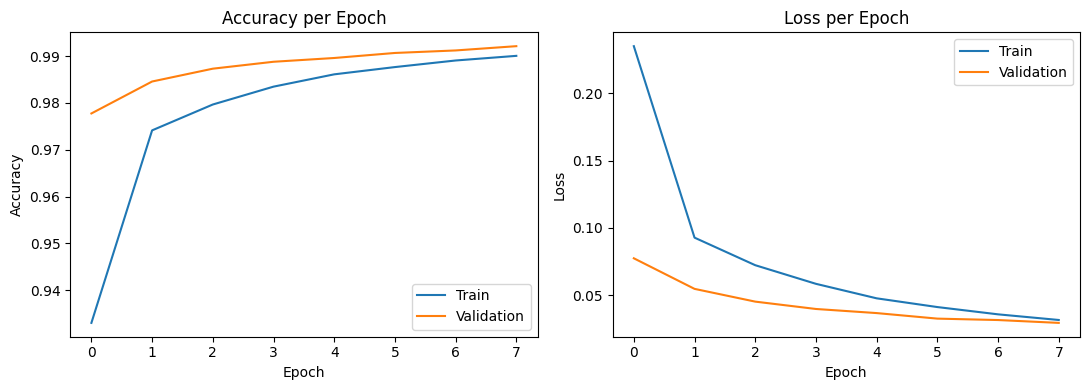

In [ ]:
# Learning curves: a large gap between train and validation suggests overfitting
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy per Epoch")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss per Epoch")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()

plt.tight_layout()
plt.show()

#**Evaluation**

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss:     {test_loss:.4f}")

# Predicted class = the letter with the highest probability
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

# Precision, recall and F1-score for each letter
print(classification_report(y_test, y_pred, target_names=letters))

Test accuracy: 0.9920
Test loss:     0.0317
              precision    recall  f1-score   support

           A       0.99      1.00      0.99      1387
           B       0.99      0.99      0.99       867
           C       0.99      0.99      0.99      2341
           D       0.96      0.98      0.97      1013
           E       0.99      1.00      1.00      1144
           F       1.00      0.97      0.99       117
           G       0.99      0.98      0.98       576
           H       0.98      0.99      0.99       722
           I       0.97      0.97      0.97       112
           J       0.99      0.98      0.98       849
           K       0.98      0.99      0.98       561
           L       0.99      1.00      0.99      1159
           M       0.99      0.99      0.99      1233
           N       0.99      0.99      0.99      1901
           O       1.00      0.99      0.99      5783
           P       0.99      1.00      0.99      1934
           Q       0.98      0.97    

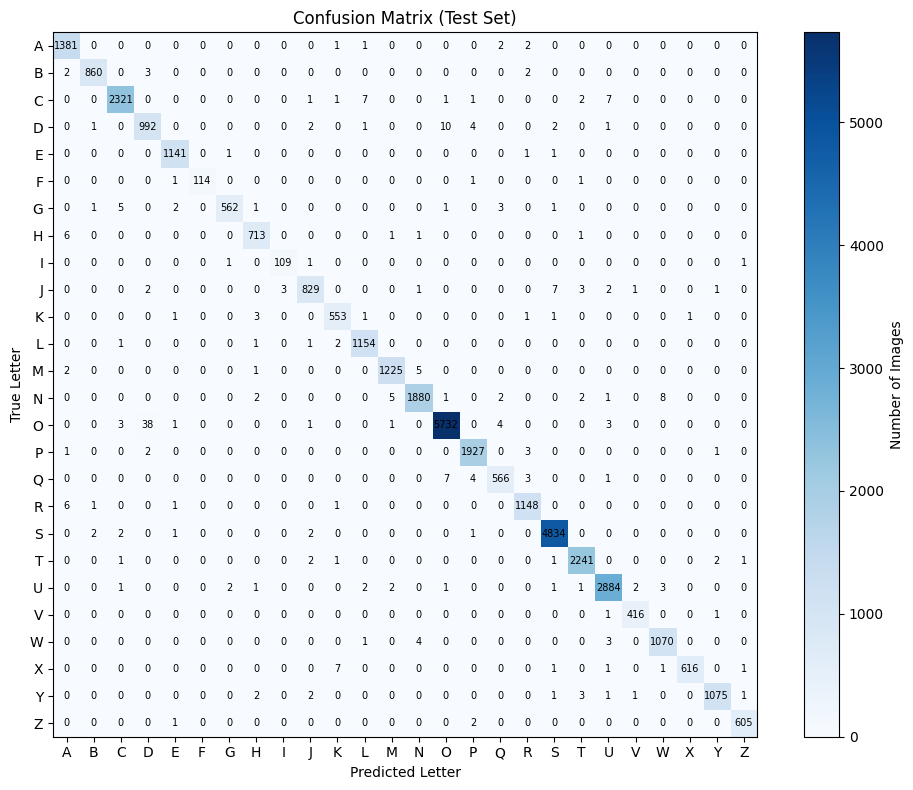

In [ ]:
# Create the confusion matrix
# Rows represent the true letters and columns represent the predicted letters
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
plt.imshow(cm, cmap="Blues")

# Add letter labels to the x-axis and y-axis
plt.xticks(range(26), letters)
plt.yticks(range(26), letters)

# Add axis labels and title
plt.xlabel("Predicted Letter")
plt.ylabel("True Letter")
plt.title("Confusion Matrix (Test Set)")

# Add a colour bar to show the number of observations
plt.colorbar(label="Number of Images")

# Add the numerical count inside each cell
for i in range(26):
    for j in range(26):
        plt.text(j, i, cm[i, j],
                 ha="center",
                 va="center",
                 fontsize=7)

plt.tight_layout()
plt.show()

In [ ]:
# Most frequent mistakes (ignore the diagonal, which holds correct predictions)
cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)
top = np.dstack(np.unravel_index(np.argsort(-cm_errors.ravel())[:5], cm_errors.shape))[0]

print("Top 5 confusions (true -> predicted):")
for t, p in top:
    print(f"  {letters[t]} -> {letters[p]}: {cm_errors[t, p]} times")

Top 5 confusions (true -> predicted):
  O -> D: 38 times
  D -> O: 10 times
  N -> W: 8 times
  X -> K: 7 times
  J -> S: 7 times


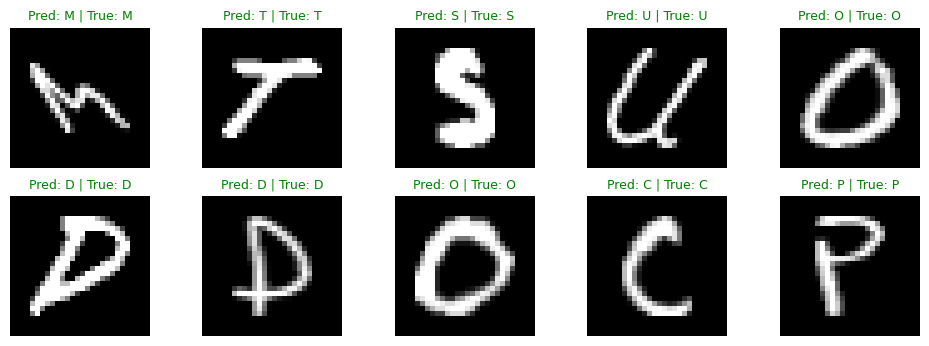

In [ ]:
# Visual check of test predictions: green = correct, red = wrong
plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    colour = "green" if y_pred[i] == y_test[i] else "red"
    plt.title(f"Pred: {letters[y_pred[i]]} | True: {letters[y_test[i]]}",
              color=colour, fontsize=9)
    plt.axis("off")
plt.show()

#**Conclusion**

Summary

A Convolutional Neural Network (CNN) was developed to automatically recognise handwritten English capital letters (A–Z) from 28 × 28 greyscale images. The image data were normalised and divided into stratified training, validation, and test sets to ensure that the 26 letter classes were appropriately represented. The CNN was trained to learn important visual features, such as edges, curves, and shapes, that distinguish one handwritten letter from another. Model performance was evaluated on unseen test data using overall accuracy, a per-letter classification report, and a confusion matrix.

Findings

The results demonstrate that a compact CNN architecture with two convolutional blocks can achieve high classification performance on the handwritten alphabet dataset. The model achieved a test accuracy of 99.2%, based on the final evaluation of the unseen test set.

The training and validation learning curves provide an indication of the model's learning behaviour and generalisation performance. When the training and validation performance remain relatively close, this suggests that the model is learning useful patterns without substantial overfitting. The classification report provides additional insight into performance for each individual letter through measures such as precision, recall, and F1-score.

The confusion matrix shows which letters are most frequently confused by the model. Misclassifications are more likely to occur between letters with visually similar handwritten shapes, particularly when different writing styles make their distinguishing features less pronounced. These errors highlight the challenges associated with recognising handwritten characters that have overlapping visual characteristics.

Limitations

Despite achieving strong classification performance, the model has several limitations. First, the dataset is not perfectly balanced across all 26 letter classes. Consequently, less frequently represented letters may have slightly lower recall or F1-scores than more frequently represented classes.

Second, the model is designed specifically for single, pre-segmented uppercase English letters. Therefore, its applicability is limited to the type of images represented in the dataset. It does not directly recognise lowercase letters, digits, complete words, or connected handwriting. In addition, differences in handwriting styles, image quality, and character positioning that are not sufficiently represented in the training data may affect performance on new real-world images.

Overall, the CNN provides an effective approach for handwritten capital-letter classification while demonstrating the importance of appropriate preprocessing, model evaluation, and analysis of class-specific errors.